# Least Square Fitting - Residuals

**Author**: SH

This notebook shows an interactive demonstration of residuals when looking at a simple linear regression model. The aim is to give a visual intuition of residuals - and what effects changing the model hyperparameters has in terms of the total sum of residuals - in lieu of having a whiteboard to sketch on.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from ipywidgets import interact
import ipywidgets as widgets

# Random number generator for white noise
rng = np.random.default_rng()

First, let's mock up our data - can just be a simple linear relationship:

$$ y_i = m x_i + C + n_i$$

where $m = 1.2$ and $C = 4$. We will also add some Gaussian white noise, $n$, to make the data look more representative. 

In [2]:
# Create ideal relation
x = np.array([1, 2, 4, 5, 7, 9])
m = 1.2
C = 4

y_true = m*x + C

# Add GWN to the data
y_meas = y_true + rng.normal(loc=0, scale=.5, size=len(x))

interactive(children=(FloatSlider(value=0.75, description='gradient', max=5.0, min=-5.0), FloatSlider(value=6.…

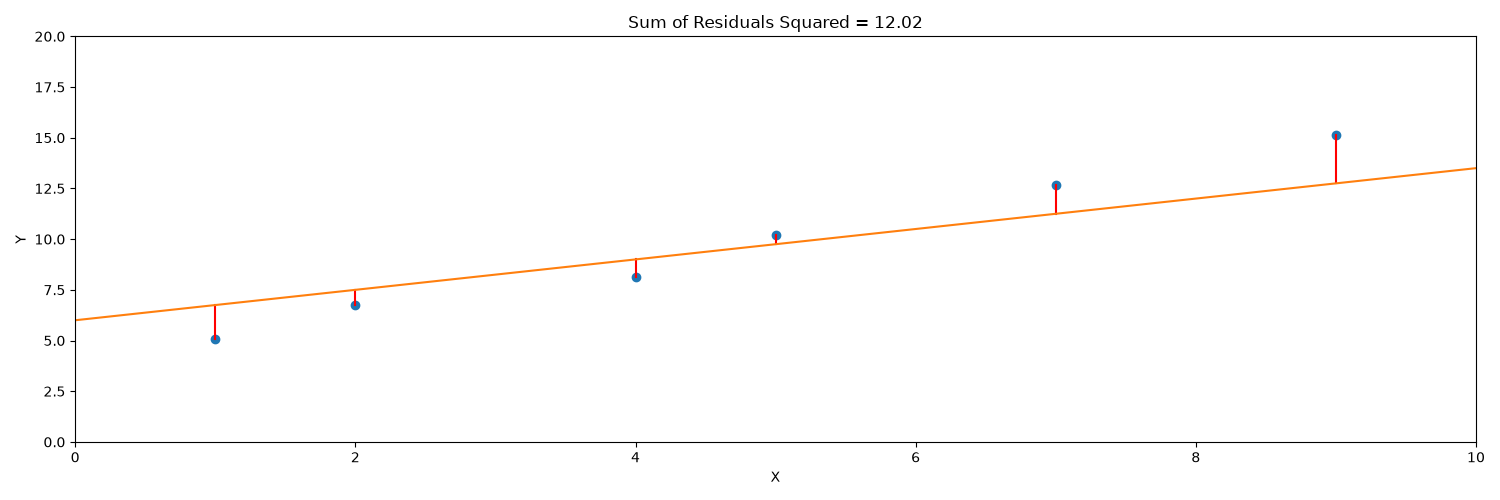

In [3]:
%matplotlib widget
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(x, y_meas, 'o')
ax.set_xlim(0, 10)
ax.set_ylim(0, 20)
ax.set_xlabel('X')
ax.set_ylabel('Y')

# Setting up line of best fit
x_fit = np.linspace(0, 10, 128)
grad = 0.75
inter = 6

# Calculate expected values
y_expected = grad*x + inter
residuals = y_meas - y_expected
residual_plots = []
for x_m, y_m, y_exp in zip(x, y_meas, y_expected):
    buff, = ax.plot([x_m, x_m], [y_m, y_exp], 'r')
    residual_plots.append(buff)

# Plot line of 'best' fit
line, = ax.plot(x_fit, grad*x_fit + inter)

r_squared = (residuals**2).sum()
ax.set_title(f'Sum of Residuals Squared = {r_squared:0.2f}')


def update(gradient: float, intercept: float) -> None:
    '''Update line of best fit

    Inputs:
        gradient: gradient of linear plot
        intercept: intercept with y-axis

    Returns:
        None
    '''
    # Calculate new expected values
    y_exp = gradient*x + intercept

    # Update residual plots
    for i, ax_res in enumerate(residual_plots):
        ax_res.set_ydata((y_meas[i], y_exp[i]))

    # Update line of best fit
    line.set_ydata(gradient*x_fit + intercept)

    # Calculate residuals and update title
    resids = ((y_meas - y_exp)**2).sum()
    ax.set_title(f'Sum of Residuals Squared = {resids:0.2f}')

    # Update
    fig.canvas.draw_idle()


_ = interact(update,
             gradient=widgets.FloatSlider(value=grad,
                                          min=-5,
                                          max=5,
                                          step=0.1),
             intercept=widgets.FloatSlider(value=inter,
                                           min=-5,
                                           max=20,
                                           step=0.25))

fig.tight_layout()

### Exploring the Cost Surface

While adjusting the values of $m$ and $C$ manually can help build intuition about how a fitted line changes, it can quickly become a tedious process. Finding the best-fitting line by trial and error is difficult, particularly when many different parameter combinations produce similar results. Instead, we can systematically evaluate every combination of $m$ and $C$
 within a specified range and calculate the corresponding cost (sum of squared residuals). This produces a *cost surface*, where each point represents the error associated with a particular choice of parameters. By visualising this surface, we can identify the location of the minimum cost and determine the values of $m$ and $C$ that provide the least-squares fit to the data.

The optimal values are: y = 1.2x + 4.00


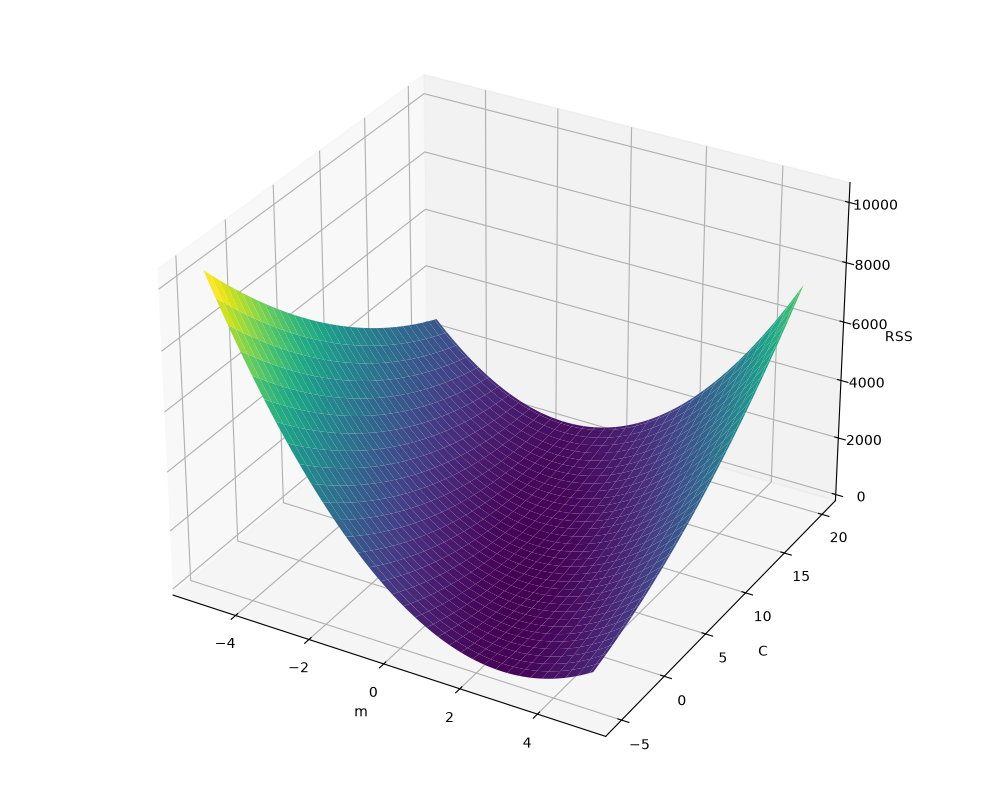

In [4]:
# Parameter ranges
m_vals = np.arange(-5, 5.1, 0.1)
C_vals = np.arange(-5, 20.25, 0.25)

# Create grid
M, C = np.meshgrid(m_vals, C_vals)

# Calculate predicted values for all M and C pairs
Y_pred = M[..., None] * x + C[..., None]

# Cost surface
RSS = np.sum((y_meas - Y_pred)**2, axis=2)

# Finding the minimum value of the cost surface - this will be minimum error = best fit
idx = np.unravel_index(np.argmin(RSS), RSS.shape)

m_opt = M[idx]
C_opt = C[idx]

print(f"The optimal values are: y = {m_opt:.1f}x + {C_opt:.2f}")

# Plotting the 3D cost surface
fig2 = plt.figure(figsize=(10,8))
ax2 = fig2.add_subplot(projection='3d')

ax2.plot_surface(
    M,
    C,
    RSS,
    cmap='viridis',
    linewidth=0
)

ax2.set_xlabel('m')
ax2.set_ylabel('C')
ax2.set_zlabel('RSS')
fig2.tight_layout()

Although the three-dimensional surface provides a useful illustration of the shape of the cost function, it can sometimes be difficult to identify the exact location of the minimum due to perspective, shading, and occlusion. A two-dimensional heatmap offers a clearer view by representing the cost using colour, allowing patterns and gradients to be seen more easily. In particular, the minimum cost region and the corresponding optimal values of $m$ and $C$ are often much easier to locate on the heatmap than on the three-dimensional surface, making it a useful tool for understanding how the least-squares solution is obtained.

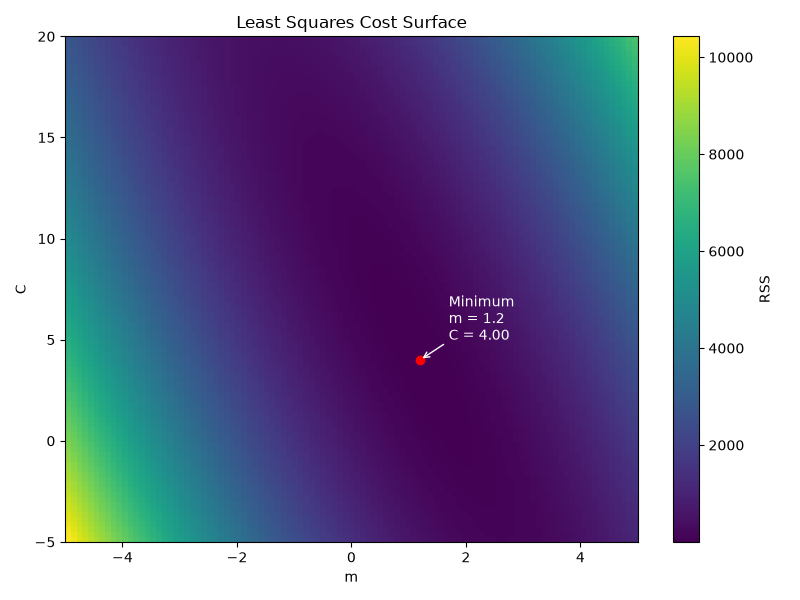

In [5]:
# Creating figure
fig3, ax3 = plt.subplots(figsize=(8,6))

im = ax3.imshow(
    RSS,
    origin='lower',
    aspect='auto',
    extent=[
        m_vals.min(),
        m_vals.max(),
        C_vals.min(),
        C_vals.max()
    ]
)

ax3.plot(m_opt, C_opt, 'ro', label='Optimal Fit')
ax3.annotate(
    f"Minimum\nm = {m_opt:.1f}\nC = {C_opt:.2f}",
    xy=(m_opt, C_opt),
    xytext=(m_opt + 0.5, C_opt + 1),
    arrowprops=dict(arrowstyle='->', color='white'),
    color="white"
)

fig3.colorbar(im, ax=ax3, label='RSS')
ax3.set_xlabel('m')
ax3.set_ylabel('C')
ax3.set_title('Least Squares Cost Surface')
fig3.tight_layout()